In [41]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [62]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          # base size, everything scales from this
plt.rcParams['axes.labelsize'] = 16     # x/y axis labels
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [63]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.255413, beta_SG = 0.549306


In [64]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique())
df

betas: [0.26 0.24 0.27 0.25] 
sizes: [    100    1000   10000  100000 1000000     300    3000   30000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.26,F_beta_Glauber,False,100,50,1000000000,100,50,2.742760e+03,1.139842e+03
1,0.26,F_beta_Glauber,False,100,50,1000000000,1000,50,9.752272e+04,3.125580e+04
2,0.26,F_beta_Glauber,False,100,50,1000000000,10000,50,3.631727e+06,1.457573e+06
3,0.26,F_beta_Glauber,False,2,50,1000000000,100,50,1.554960e+03,8.790488e+02
4,0.26,F_beta_Glauber,False,2,50,1000000000,1000,50,6.084382e+04,3.373466e+04
5,0.26,F_beta_Glauber,False,2,50,1000000000,10000,50,1.729570e+06,9.764400e+05
6,0.26,F_beta_Glauber,False,2,50,1000000000,100000,46,2.401471e+08,2.019343e+08
7,0.26,F_beta_Glauber,False,2,50,1000000000,1000000,0,NaN,NaN
8,0.26,F_beta_Glauber,False,2,50,1000000000,300,50,8.500700e+03,3.677366e+03
9,0.26,F_beta_Glauber,False,2,50,1000000000,3000,50,3.346105e+05,2.012408e+05


# Proba of coalescence

In [67]:
max_iter_plot = 10**9
n_configs_plot = 2
N_plot = [10**3,10**4,10**5,10**6]
mask = (
    (df['N'].isin(N_plot)) &
    (df['n_configs'] == n_configs_plot) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
4,0.26,F_beta_Glauber,False,2,50,1000000000,1000,50,6.084382e+04,3.373466e+04
5,0.26,F_beta_Glauber,False,2,50,1000000000,10000,50,1.729570e+06,9.764400e+05
6,0.26,F_beta_Glauber,False,2,50,1000000000,100000,46,2.401471e+08,2.019343e+08
7,0.26,F_beta_Glauber,False,2,50,1000000000,1000000,0,NaN,NaN
16,0.24,F_beta_Glauber,False,2,50,1000000000,1000,50,3.761858e+04,1.341857e+04
17,0.24,F_beta_Glauber,False,2,50,1000000000,10000,50,9.001974e+05,3.073985e+05
18,0.24,F_beta_Glauber,False,2,50,1000000000,100000,50,1.489301e+07,3.753860e+06
19,0.24,F_beta_Glauber,False,2,50,1000000000,1000000,50,2.250668e+08,4.292551e+07
27,0.27,F_beta_Glauber,False,2,50,1000000000,1000,50,7.568552e+04,5.379697e+04
28,0.27,F_beta_Glauber,False,2,50,1000000000,10000,50,5.931300e+06,4.739495e+06


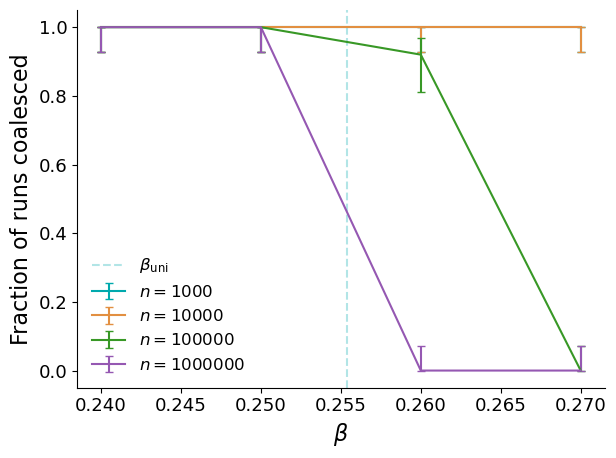

In [68]:
fig, ax = plt.subplots()

for N in sorted(df_filtered['N'].unique()):
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    if graph_type == 'EA2D' or graph_type == 'F2D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**2}$', capsize=3)
    elif graph_type == 'EA3D' or graph_type == 'F3D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**3}$', capsize=3)
    else:
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N}$', capsize=3)
ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [69]:
#fig.savefig(f'../results/perm/coal_DS_frac_{graph_type}_{coup_type}_d{d}.png', dpi=600, bbox_inches='tight')

# Scaling of coalescence times

In [70]:
max_iter_plot = 10**9
n_configs_plot = 2

if graph_type == 'ER' and coup_type == 'ising':
    beta_plot = df['beta'].unique() #[0.24,0.25] # beta selection for plotting
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['n_configs'] == n_configs_plot) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
3,0.26,F_beta_Glauber,False,2,50,1000000000,100,50,1.554960e+03,8.790488e+02
4,0.26,F_beta_Glauber,False,2,50,1000000000,1000,50,6.084382e+04,3.373466e+04
5,0.26,F_beta_Glauber,False,2,50,1000000000,10000,50,1.729570e+06,9.764400e+05
8,0.26,F_beta_Glauber,False,2,50,1000000000,300,50,8.500700e+03,3.677366e+03
9,0.26,F_beta_Glauber,False,2,50,1000000000,3000,50,3.346105e+05,2.012408e+05
10,0.26,F_beta_Glauber,False,2,50,1000000000,30000,50,1.667943e+07,1.004979e+07
15,0.24,F_beta_Glauber,False,2,50,1000000000,100,50,1.482660e+03,9.658065e+02
16,0.24,F_beta_Glauber,False,2,50,1000000000,1000,50,3.761858e+04,1.341857e+04
17,0.24,F_beta_Glauber,False,2,50,1000000000,10000,50,9.001974e+05,3.073985e+05
18,0.24,F_beta_Glauber,False,2,50,1000000000,100000,50,1.489301e+07,3.753860e+06


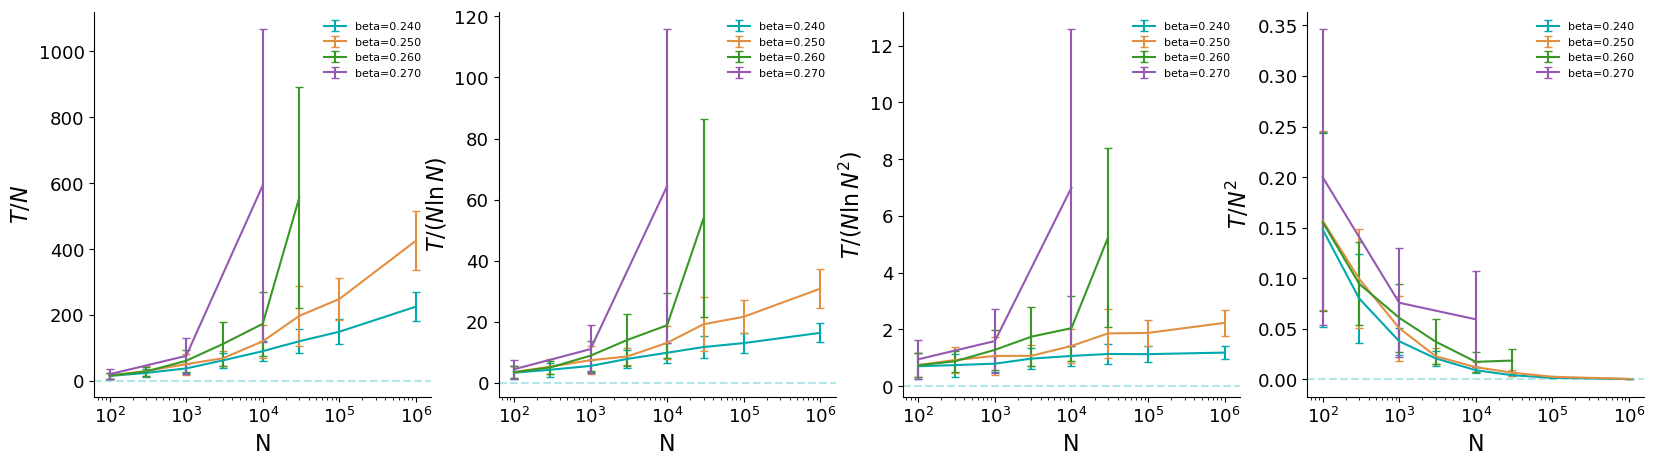

In [74]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
betas_to_exclude = []
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        if beta in betas_to_exclude:
            continue
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()

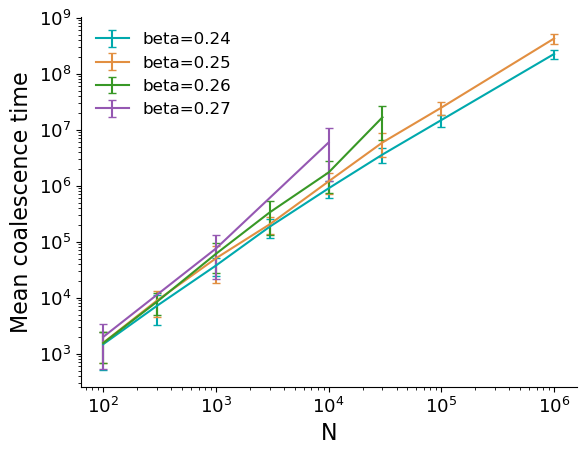

In [72]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_configs'] == n_configs_plot) &
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in sorted(df_filtered['beta'].unique()):
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values
    plt.errorbar(N, T,
                yerr=sT,
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()